In [1]:
import os
from google.colab import files

os.makedirs("data", exist_ok=True)
uploaded = files.upload()   # chọn khach_vay.csv và gia_nha.csv

Saving gia_nha.csv to gia_nha (1).csv
Saving khach_vay.csv to khach_vay (1).csv


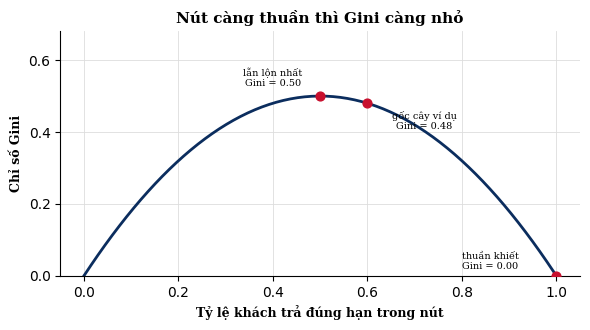

In [38]:
import numpy as np
import matplotlib.pyplot as plt

p = np.linspace(0, 1, 200)
G = 1 - p**2 - (1 - p)**2

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(p, G, color="#0b2d5e", linewidth=2)

# Ba điểm đỏ: lẫn lộn nhất, gốc cây ví dụ, thuần khiết
diem = [(0.5, "lẫn lộn nhất\nGini = 0.50", (0.40, 0.55)),
        (0.6, "gốc cây ví dụ\nGini = 0.48", (0.72, 0.43)),
        (1.0, "thuần khiết\nGini = 0.00", (0.86, 0.04))]
for x, nhan, (tx, ty) in diem:
    g = 1 - x**2 - (1 - x)**2
    ax.scatter(x, g, color="#c8102e", s=40, zorder=3)
    ax.text(tx, ty, nhan, ha="center", va="center",
            fontsize=7, family="serif")

ax.set_title("Nút càng thuần thì Gini càng nhỏ",
             fontsize=11, fontweight="bold", family="serif")
ax.set_xlabel("Tỷ lệ khách trả đúng hạn trong nút",
              fontsize=9, fontweight="bold", family="serif")
ax.set_ylabel("Chỉ số Gini", fontsize=9, fontweight="bold", family="serif")
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(0, 0.68)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticks([0, 0.2, 0.4, 0.6])
ax.grid(True, color="#dddddd", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("hinh1_gini.png", dpi=200)
plt.show()

In [2]:
for ten in uploaded:
    os.replace(ten, f"data/{ten}")
print(os.listdir("data"))

['khach_vay (1).csv', 'gia_nha (1).csv']


In [3]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

nho = pd.DataFrame({
    "thu_nhap":        [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han":    [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()

In [4]:
def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)

In [5]:
g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")

Gini cua nut goc: 0.4800


In [6]:
thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print("  nguong  Gini sau chia  Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f"  {nguong:6.1f}  {g:13.4f}  {g_goc - g:9.4f}")

Cau hoi 'thu_nhap <= nguong ?'
  nguong  Gini sau chia  Gini giam
     7.0         0.4000     0.0800
     8.5         0.4750     0.0050
    10.0         0.4190     0.0610
    12.0         0.3167     0.1633
    14.0         0.4000     0.0800
    16.5         0.4500     0.0300
    19.0         0.3429     0.1371
    22.5         0.4000     0.0800
    27.5         0.4444     0.0356


In [7]:
viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f"  Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")

Cau hoi 'co viec on dinh ?'
  Gini sau chia 0.4190, Gini giam 0.0610


In [8]:
cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



In [11]:
import os

for cu, moi in [("data/khach_vay (1).csv", "data/khach_vay.csv"),
                ("data/gia_nha (1).csv", "data/gia_nha.csv")]:
    if os.path.exists(cu):
        os.rename(cu, moi)

print(os.listdir("data"))

['gia_nha.csv', 'khach_vay.csv']


In [12]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("data/khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49


In [13]:
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

In [14]:
cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0



In [15]:
a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc      : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")

Accuracy tap hoc      : 0.7978
Accuracy tap kiem tra : 0.7467


In [16]:
moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Khach 1: dung han, xac suat dung han 0.84
Khach 2: tre han, xac suat dung han 0.15


In [17]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

In [18]:
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f"  do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f"  tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")

Cay moc tu do
  do sau 13, so la 92
  tap hoc 1.0000, tap kiem tra 0.7667


In [19]:
print("Do sau  tap hoc  kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f"  {d:2d}     {hoc:.4f}   {diem[d]:.4f}")
d_tot = max(diem, key=diem.get)

Do sau  tap hoc  kiem dinh cheo
   1     0.7467   0.7244
   2     0.7711   0.7378
   3     0.8000   0.7511
   4     0.8644   0.8089
   5     0.8978   0.8333
   6     0.9133   0.8156
   7     0.9400   0.8067
   8     0.9600   0.7733
   9     0.9800   0.7800
  10     0.9911   0.7822
  11     0.9933   0.7756
  12     0.9978   0.7778
  13     1.0000   0.7733
  14     1.0000   0.7733
  15     1.0000   0.7733


In [20]:
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


In [21]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)

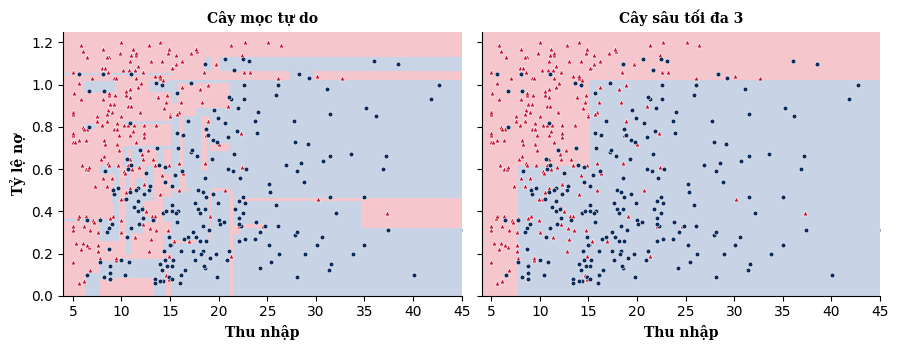

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
cot = ["thu_nhap", "ty_le_no"]
X = df[cot]
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai cây chỉ học trên hai cột để vẽ được trên mặt phẳng
cay_tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
cay_sau_3 = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_tr, y_tr)

# Lưới điểm phủ toàn bộ khung hình
xx, yy = np.meshgrid(np.linspace(4, 45, 500), np.linspace(0, 1.25, 500))
luoi = pd.DataFrame({"thu_nhap": xx.ravel(), "ty_le_no": yy.ravel()})

nen = ListedColormap(["#f5c6cb", "#c9d3e6"])   # hồng: trễ hạn, xanh nhạt: đúng hạn
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)

for ax, cay, tieu_de in [(axes[0], cay_tu_do, "Cây mọc tự do"),
                         (axes[1], cay_sau_3, "Cây sâu tối đa 3")]:
    vung = cay.predict(luoi).reshape(xx.shape)
    ax.pcolormesh(xx, yy, vung, cmap=nen, shading="auto")

    tre = y_tr == 0
    ax.scatter(X_tr.loc[tre, "thu_nhap"], X_tr.loc[tre, "ty_le_no"],
               marker="^", s=12, color="#c8102e",
               edgecolor="white", linewidth=0.4)
    ax.scatter(X_tr.loc[~tre, "thu_nhap"], X_tr.loc[~tre, "ty_le_no"],
               marker="o", s=12, color="#0b2d5e",
               edgecolor="white", linewidth=0.4)

    ax.set_title(tieu_de, fontsize=10, fontweight="bold", family="serif")
    ax.set_xlabel("Thu nhập", fontsize=10, fontweight="bold", family="serif")
    ax.set_xlim(4, 45)
    ax.set_ylim(0, 1.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Tỷ lệ nợ", fontsize=10, fontweight="bold", family="serif")

plt.tight_layout()
plt.savefig("hinh3_bien_quyet_dinh.png", dpi=200)
plt.show()

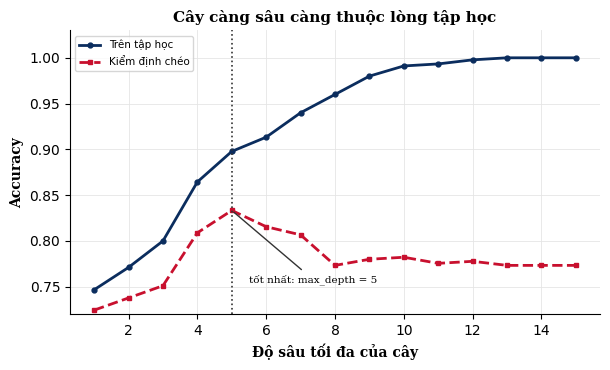

Do sau tot nhat = 5, diem kiem dinh cheo = 0.8333


In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Tính accuracy tập học và điểm kiểm định chéo cho từng độ sâu
do_sau = list(range(1, 16))
hoc, cheo = [], []
for d in do_sau:
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    cheo.append(cross_val_score(mh, X_tr, y_tr, cv=5).mean())
    hoc.append(accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr)))

d_tot = do_sau[int(np.argmax(cheo))]

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(do_sau, hoc, "-o", color="#0b2d5e", linewidth=2,
        markersize=3.5, label="Trên tập học")
ax.plot(do_sau, cheo, "--s", color="#c8102e", linewidth=2,
        markersize=3.5, label="Kiểm định chéo")

# Đường dọc và chú thích tại độ sâu tốt nhất
ax.axvline(d_tot, color="#333333", linestyle=":", linewidth=1.2)
ax.annotate(f"tốt nhất: max_depth = {d_tot}",
            xy=(d_tot, max(cheo)), xytext=(d_tot + 0.5, 0.755),
            fontsize=7.5, family="serif",
            arrowprops=dict(arrowstyle="-", color="#333333"))

ax.set_title("Cây càng sâu càng thuộc lòng tập học",
             fontsize=11, fontweight="bold", family="serif")
ax.set_xlabel("Độ sâu tối đa của cây",
              fontsize=10, fontweight="bold", family="serif")
ax.set_ylabel("Accuracy", fontsize=10, fontweight="bold", family="serif")
ax.set_xticks([2, 4, 6, 8, 10, 12, 14])
ax.set_ylim(0.72, 1.03)
ax.grid(True, color="#e5e5e5", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", fontsize=7.5, frameon=True)

plt.tight_layout()
plt.savefig("hinh4_do_sau.png", dpi=200)
plt.show()
print(f"Do sau tot nhat = {d_tot}, diem kiem dinh cheo = {max(cheo):.4f}")

In [22]:
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

In [23]:
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

In [24]:
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

In [25]:
print("Accuracy tren tap kiem tra")
print(f"  du lieu goc         : {accuracy_score(y_te, du_goc):.4f}")
print(f"  da chuan hoa        : {accuracy_score(y_te, du_chuan):.4f}")
print(f"  thu nhap nghin dong : {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f"  da chuan hoa        : {(du_chuan != du_goc).sum()}")
print(f"  thu nhap nghin dong : {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f"  du lieu goc         : {goc.tree_.threshold[0]:.2f}")
print(f"  thu nhap nghin dong : {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
  du lieu goc         : 0.8533
  da chuan hoa        : 0.8533
  thu nhap nghin dong : 0.8533

So khach bi doan khac cay goc
  da chuan hoa        : 0
  thu nhap nghin dong : 0

Nguong cua cau hoi goc
  du lieu goc         : 15.05
  thu nhap nghin dong : 15050.00


In [26]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

In [27]:
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")

Boc 450 lan, co 286 khach khac nhau (64%)


In [28]:
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f"  tap hoc      : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f"  tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}")

Rung 200 cay
  tap hoc      : 1.0000
  tap kiem tra : 0.9000


In [29]:
print("So cay   accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f"  {m:4d}   {accuracy_score(y_te, r.predict(X_te)):.4f}")

So cay   accuracy tap kiem tra
     1   0.7933
    10   0.8467
    50   0.8733
   200   0.9000
   400   0.9000


In [30]:
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}
print("Mo hinh          tap hoc  tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:14s} {a:.4f}   {b:.4f}")

Mo hinh          tap hoc  tap kiem tra
  Cay moc tu do  1.0000   0.7667
  Cay sau 5      0.8978   0.8533
  Rung 200 cay   1.0000   0.9000


In [31]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

In [32]:
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))

Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0


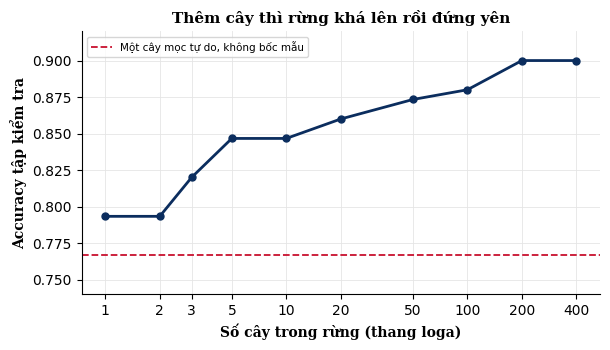

   1 cay: 0.7933
   2 cay: 0.7933
   3 cay: 0.8200
   5 cay: 0.8467
  10 cay: 0.8467
  20 cay: 0.8600
  50 cay: 0.8733
 100 cay: 0.8800
 200 cay: 0.9000
 400 cay: 0.9000
Cay moc tu do: 0.7667


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Accuracy tập kiểm tra của rừng theo số cây
so_cay = [1, 2, 3, 5, 10, 20, 50, 100, 200, 400]
acc = []
for m in so_cay:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    acc.append(accuracy_score(y_te, r.predict(X_te)))

# Một cây mọc tự do để làm mốc so sánh
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
acc_tu_do = accuracy_score(y_te, tu_do.predict(X_te))

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(so_cay, acc, "-o", color="#0b2d5e", linewidth=2, markersize=5)
ax.axhline(acc_tu_do, color="#c8102e", linestyle="--", linewidth=1.3,
           label="Một cây mọc tự do, không bốc mẫu")

ax.set_xscale("log")
ax.set_xticks(so_cay)
ax.set_xticklabels([str(m) for m in so_cay])
ax.minorticks_off()

ax.set_title("Thêm cây thì rừng khá lên rồi đứng yên",
             fontsize=11, fontweight="bold", family="serif")
ax.set_xlabel("Số cây trong rừng (thang loga)",
              fontsize=10, fontweight="bold", family="serif")
ax.set_ylabel("Accuracy tập kiểm tra",
              fontsize=10, fontweight="bold", family="serif")
ax.set_ylim(0.74, 0.92)
ax.grid(True, color="#e5e5e5", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", fontsize=7.5, frameon=True)

plt.tight_layout()
plt.savefig("hinh5_so_cay.png", dpi=200)
plt.show()

for m, a in zip(so_cay, acc):
    print(f"{m:4d} cay: {a:.4f}")
print(f"Cay moc tu do: {acc_tu_do:.4f}")

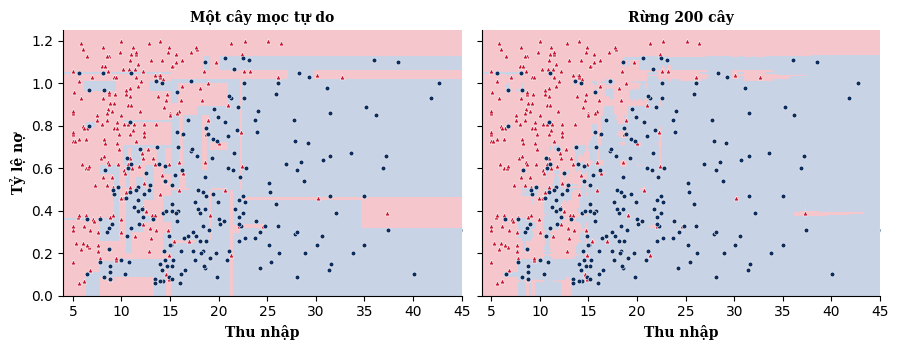

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
cot = ["thu_nhap", "ty_le_no"]
X = df[cot]
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai mô hình chỉ học trên hai cột để vẽ được trên mặt phẳng
cay_tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
rung = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_tr, y_tr)

# Lưới điểm phủ toàn bộ khung hình
xx, yy = np.meshgrid(np.linspace(4, 45, 400), np.linspace(0, 1.25, 400))
luoi = pd.DataFrame({"thu_nhap": xx.ravel(), "ty_le_no": yy.ravel()})

nen = ListedColormap(["#f5c6cb", "#c9d3e6"])   # hồng: trễ hạn, xanh nhạt: đúng hạn
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)

for ax, mh, tieu_de in [(axes[0], cay_tu_do, "Một cây mọc tự do"),
                        (axes[1], rung, "Rừng 200 cây")]:
    vung = mh.predict(luoi).reshape(xx.shape)
    ax.pcolormesh(xx, yy, vung, cmap=nen, shading="auto")

    tre = y_tr == 0
    ax.scatter(X_tr.loc[tre, "thu_nhap"], X_tr.loc[tre, "ty_le_no"],
               marker="^", s=12, color="#c8102e",
               edgecolor="white", linewidth=0.4)
    ax.scatter(X_tr.loc[~tre, "thu_nhap"], X_tr.loc[~tre, "ty_le_no"],
               marker="o", s=12, color="#0b2d5e",
               edgecolor="white", linewidth=0.4)

    ax.set_title(tieu_de, fontsize=10, fontweight="bold", family="serif")
    ax.set_xlabel("Thu nhập", fontsize=10, fontweight="bold", family="serif")
    ax.set_xlim(4, 45)
    ax.set_ylim(0, 1.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Tỷ lệ nợ", fontsize=10, fontweight="bold", family="serif")

plt.tight_layout()
plt.savefig("hinh6_cay_va_rung.png", dpi=200)
plt.show()

In [33]:
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


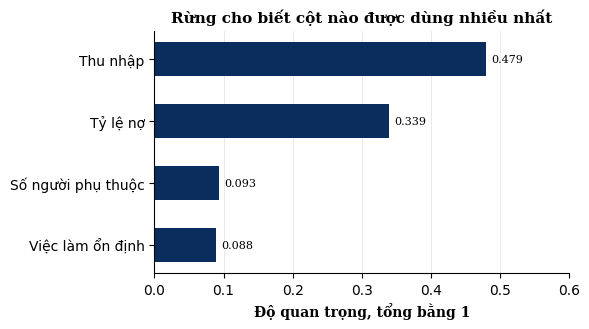

thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088


In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns)

# Tên hiển thị tiếng Việt, sắp xếp tăng dần để cột lớn nhất nằm trên cùng
ten_hien_thi = {
    "thu_nhap": "Thu nhập",
    "ty_le_no": "Tỷ lệ nợ",
    "so_nguoi_phu_thuoc": "Số người phụ thuộc",
    "co_viec_on_dinh": "Việc làm ổn định",
}
qt = qt.sort_values(ascending=True)
nhan = [ten_hien_thi[c] for c in qt.index]

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.barh(nhan, qt.values, color="#0b2d5e", height=0.55)

# Ghi giá trị cạnh đầu mỗi cột
for i, v in enumerate(qt.values):
    ax.text(v + 0.008, i, f"{v:.3f}", va="center",
            fontsize=8, family="serif")

ax.set_title("Rừng cho biết cột nào được dùng nhiều nhất",
             fontsize=11, fontweight="bold", family="serif")
ax.set_xlabel("Độ quan trọng, tổng bằng 1",
              fontsize=10, fontweight="bold", family="serif")
ax.set_xlim(0, 0.6)
ax.set_xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
ax.grid(True, axis="x", color="#e5e5e5", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("hinh7_do_quan_trong.png", dpi=200)
plt.show()
print(qt.sort_values(ascending=False).round(3).to_string())

In [34]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

In [35]:
cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Cay hoi quy sau 3 co {cay.get_n_leaves()} la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]



In [36]:
print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  Cay sau 3  : {mae_cay:.4f}")
print(f"  Duong thang: {mae_duong:.4f}")

MAE tren tap kiem tra (ty dong)
  Cay sau 3  : 0.5039
  Duong thang: 0.2578


In [37]:
can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich   cay   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], cay.predict(can_moi),
                    duong.predict(can_moi)):
    print(f"  {dt:6.0f} m2  {a:6.2f}  {b:6.2f}")

Du doan cho bon can moi (ty dong)
  dien tich   cay   duong thang
      60 m2    4.92    5.12
     100 m2    8.32    8.24
     150 m2    9.40   12.13
     250 m2    9.40   19.91


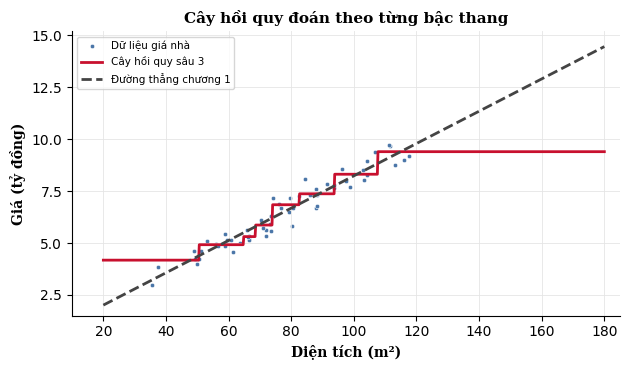

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

cay = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

# Lưới diện tích từ 20 tới 180 m2 để vẽ đường dự đoán
luoi = pd.DataFrame({"dien_tich": np.linspace(20, 180, 800)})

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.scatter(df["dien_tich"], df["gia"], s=10, color="#4a76a8",
           edgecolor="white", linewidth=0.4, label="Dữ liệu giá nhà")
ax.plot(luoi["dien_tich"], cay.predict(luoi), color="#c8102e",
        linewidth=2, label="Cây hồi quy sâu 3")
ax.plot(luoi["dien_tich"], duong.predict(luoi), color="#444444",
        linewidth=2, linestyle="--", label="Đường thẳng chương 1")

ax.set_title("Cây hồi quy đoán theo từng bậc thang",
             fontsize=11, fontweight="bold", family="serif")
ax.set_xlabel("Diện tích (m²)", fontsize=10, fontweight="bold", family="serif")
ax.set_ylabel("Giá (tỷ đồng)", fontsize=10, fontweight="bold", family="serif")
ax.set_xticks(range(20, 181, 20))
ax.set_yticks([2.5, 5.0, 7.5, 10.0, 12.5, 15.0])
ax.set_xlim(10, 185)
ax.set_ylim(1.5, 15.2)
ax.grid(True, color="#e5e5e5", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", fontsize=7.5, frameon=True)

plt.tight_layout()
plt.savefig("hinh8_cay_hoi_quy.png", dpi=200)
plt.show()